In [1]:
import gymnasium as gym
import numpy as np

env = gym.make("CartPole-v1")
print(env.observation_space, env.action_space)

obs, _ = env.reset(seed=0)
print("obs:", obs)

total, done = 0.0, False
while not done:
    obs, r, term, trunc, _ = env.step(env.action_space.sample())
    total += r
    done = term or trunc
print("random episode reward:", total)

scores = []
for _ in range(100):
    env.reset()
    total, done = 0.0, False
    while not done:
        _, r, term, trunc, _ = env.step(env.action_space.sample())
        total += r
        done = term or trunc
    scores.append(total)
print("random baseline:", np.mean(scores))


Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) Discrete(2)
obs: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
random episode reward: 21.0
random baseline: 23.88


In [2]:
vis = gym.make("CartPole-v1", render_mode="human")
vis.reset(seed=0)
for _ in range(200):
    _, _, term, trunc, _ = vis.step(vis.action_space.sample())
    if term or trunc:
        vis.reset()
vis.close()


In [3]:
import random
from collections import deque

import torch
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

def make_qnet():
    return nn.Sequential(
        nn.Linear(4, 128), nn.ReLU(),
        nn.Linear(128, 128), nn.ReLU(),
        nn.Linear(128, 2),
    ).to(device)

q = make_qnet()
s, _ = env.reset(seed=0)
with torch.no_grad():
    print(q(torch.tensor(s, dtype=torch.float32, device=device)))


cuda
tensor([0.0481, 0.0130], device='cuda:0')


In [4]:
def act(q, s, eps):
    if random.random() < eps:
        return random.randrange(2)
    with torch.no_grad():
        s_t = torch.tensor(s, dtype=torch.float32, device=device)
        return int(q(s_t).argmax())


In [5]:
class Replay:
    def __init__(self, cap=50_000):
        self.buf = deque(maxlen=cap)

    def push(self, s, a, r, ns, done):
        self.buf.append((s, a, r, ns, float(done)))

    def sample(self, n):
        s, a, r, ns, d = zip(*random.sample(self.buf, n))
        f = lambda x, dt: torch.tensor(np.array(x), dtype=dt, device=device)
        return (f(s, torch.float32), f(a, torch.int64), f(r, torch.float32),
                f(ns, torch.float32), f(d, torch.float32))

    def __len__(self):
        return len(self.buf)


In [6]:
def evaluate(q, n=20):
    e = gym.make("CartPole-v1")
    scores = []
    for _ in range(n):
        s, _ = e.reset()
        total, done = 0.0, False
        while not done:
            s, r, term, trunc, _ = e.step(act(q, s, 0.0))   # eps=0, greedy
            total += r
            done = term or trunc
        scores.append(total)
    return np.mean(scores), np.min(scores), np.max(scores)

In [15]:
def train(n_episodes=500, gamma=0.99, lr=1e-3, batch=64,
          eps_start=1.0, eps_end=0.05, eps_decay=0.995,
          target_sync=500, warmup=1000):
    q = make_qnet()
    target = make_qnet()
    target.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    buf = Replay()
    eps, steps, returns = eps_start, 0, []
    best_score, best_state, eval_log = -1, None, []
    for ep in range(n_episodes):
        s, _ = env.reset()
        total = 0.0
        while True:
            a = act(q, s, eps)
            ns, r, term, trunc, _ = env.step(a)
            buf.push(s, a, r, ns, term)        # term, NOT term or trunc — see below
            s, total, steps = ns, total + r, steps + 1

            if len(buf) >= warmup:
                bs, ba, br, bns, bd = buf.sample(batch)
                qsa = q(bs).gather(1, ba.unsqueeze(1)).squeeze(1)   # Q(s,a) for the action taken
                with torch.no_grad():
                    y = br + gamma * target(bns).max(1).values * (1 - bd)
                loss = nn.functional.smooth_l1_loss(qsa, y)
                opt.zero_grad()
                loss.backward()
                opt.step()

            if steps % target_sync == 0:
                target.load_state_dict(q.state_dict())

            if term or trunc:
                break

        eps = max(eps_end, eps * eps_decay)
        returns.append(total)
        if (ep + 1) % 25 == 0:
            score = evaluate(q, n=5)[0]
            eval_log.append((ep + 1, score))
            if score > best_score:
                best_score, best_state = score, {k: v.clone() for k, v in q.state_dict().items()}
            print(f"ep {ep+1:4d}  eps={eps:.2f}  avg100={np.mean(returns[-100:]):6.1f}  greedy={score:6.1f}")

    q.load_state_dict(best_state)
    return q, returns, eval_log

q, returns, eval_log = train()
evaluate(q)

ep   25  eps=0.88  avg100=  24.5  greedy=   9.8
ep   50  eps=0.78  avg100=  22.2  greedy=   9.2
ep   75  eps=0.69  avg100=  20.2  greedy=   9.8
ep  100  eps=0.61  avg100=  20.1  greedy=   8.8
ep  125  eps=0.53  avg100=  20.0  greedy= 108.6
ep  150  eps=0.47  avg100=  27.2  greedy= 114.4
ep  175  eps=0.42  avg100=  41.4  greedy= 211.8
ep  200  eps=0.37  avg100=  55.4  greedy= 120.2
ep  225  eps=0.32  avg100=  63.6  greedy= 108.6
ep  250  eps=0.29  avg100=  64.2  greedy=  93.6
ep  275  eps=0.25  avg100=  63.5  greedy= 107.6
ep  300  eps=0.22  avg100=  58.9  greedy= 101.8
ep  325  eps=0.20  avg100=  58.8  greedy= 113.6
ep  350  eps=0.17  avg100=  59.5  greedy= 130.6
ep  375  eps=0.15  avg100=  65.3  greedy= 420.4
ep  400  eps=0.13  avg100=  70.5  greedy= 106.6
ep  425  eps=0.12  avg100=  95.0  greedy= 136.8
ep  450  eps=0.10  avg100= 118.4  greedy=  87.2
ep  475  eps=0.09  avg100= 140.0  greedy= 166.4
ep  500  eps=0.08  avg100= 171.8  greedy= 142.8


(np.float64(402.4), np.float64(103.0), np.float64(500.0))

In [7]:
def train(
    n_episodes=500, gamma=0.99, lr=1e-3, batch=64, warmup=1000,
    eps_start=1.0, eps_end=0.05, eps_decay=0.995,
    eps_decay_steps=None,          # set -> linear decay on env STEPS instead of episodes
    target_sync=500, tau=None,     # tau set -> Polyak soft update (target_sync ignored)
    grad_clip=None,                # set -> clip_grad_value_
    truncate_as_terminal=False,    # True -> the truncation bug, on purpose
    eval_every=25, eval_n=5, seed=0, log=True,
):
    """Defaults are the baseline. Every experiment is one kwarg away."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")

    q = make_qnet()
    target = make_qnet()
    target.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    buf = Replay()

    eps, steps, returns, eval_log = eps_start, 0, [], []
    best_score, best_state = -1.0, None

    for ep in range(n_episodes):
        s, _ = env.reset()
        total = 0.0
        while True:
            a = act(q, s, eps)
            ns, r, term, trunc, _ = env.step(a)
            buf.push(s, a, r, ns, (term or trunc) if truncate_as_terminal else term)
            s, total, steps = ns, total + r, steps + 1

            if len(buf) >= warmup:
                bs, ba, br, bns, bd = buf.sample(batch)
                qsa = q(bs).gather(1, ba.unsqueeze(1)).squeeze(1)      # Q(s,a) taken
                with torch.no_grad():
                    y = br + gamma * target(bns).max(1).values * (1 - bd)
                loss = nn.functional.smooth_l1_loss(qsa, y)
                opt.zero_grad()
                loss.backward()
                if grad_clip is not None:
                    torch.nn.utils.clip_grad_value_(q.parameters(), grad_clip)
                opt.step()

                if tau is not None:                                     # soft target update
                    with torch.no_grad():
                        for tp, p in zip(target.parameters(), q.parameters()):
                            tp.mul_(1 - tau).add_(tau * p)

            if tau is None and steps % target_sync == 0:                # hard target sync
                target.load_state_dict(q.state_dict())

            if eps_decay_steps is not None:
                eps = max(eps_end, eps_start - steps / eps_decay_steps)

            if term or trunc:
                break

        if eps_decay_steps is None:
            eps = max(eps_end, eps * eps_decay)
        returns.append(total)

        if (ep + 1) % eval_every == 0:
            score = evaluate(q, n=eval_n)[0]
            eval_log.append((ep + 1, score))
            if score > best_score:                       # keep the best policy we ever saw
                best_score = score
                best_state = {k: v.clone() for k, v in q.state_dict().items()}
            if log:
                print(f"ep {ep+1:4d}  eps={eps:.2f}  "
                      f"avg100={np.mean(returns[-100:]):6.1f}  greedy={score:6.1f}")

    if best_state is not None:
        q.load_state_dict(best_state)
    return {"q": q, "returns": returns, "eval_log": eval_log, "best": best_score}

In [8]:
EXPERIMENTS = {
    "baseline":            {},
    "soft target tau":     dict(tau=0.005),
    "eps decay on steps":  dict(eps_decay_steps=10_000),
    "grad clip":           dict(grad_clip=100),
    "ABL no target net":   dict(tau=1.0),                   # target == online net
    "ABL truncation bug":  dict(truncate_as_terminal=True), # "time limit == death"
    "ABL gamma=1.0":       dict(gamma=1.0),                 # undiscounted
}

results = {}
for name, kw in EXPERIMENTS.items():
    print(f"=== {name} {kw} ===")
    results[name] = train(eval_n=3, log=False, **kw)
    print(f"    best greedy eval: {results[name]['best']:.1f}")

=== baseline {} ===
    best greedy eval: 213.3
=== soft target tau {'tau': 0.005} ===
    best greedy eval: 500.0
=== eps decay on steps {'eps_decay_steps': 10000} ===
    best greedy eval: 257.7
=== grad clip {'grad_clip': 100} ===
    best greedy eval: 384.0
=== ABL no target net {'tau': 1.0} ===
    best greedy eval: 90.7
=== ABL truncation bug {'truncate_as_terminal': True} ===
    best greedy eval: 248.7
=== ABL gamma=1.0 {'gamma': 1.0} ===
    best greedy eval: 184.7


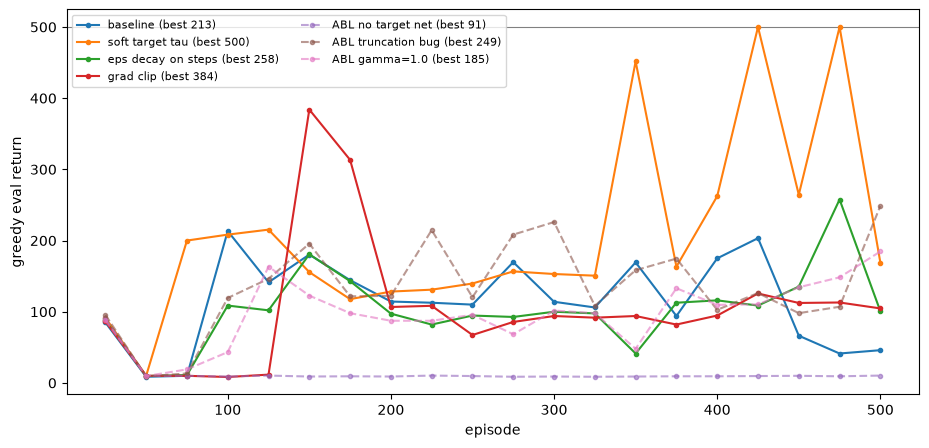

experiment                best   final  mean last5
baseline                 213.3    46.0       106.4
soft target tau          500.0   169.0       339.1
eps decay on steps       257.7   100.7       143.7
grad clip                384.0   104.7       110.1
ABL no target net         90.7    10.3         9.7
ABL truncation bug       248.7   248.7       136.5
ABL gamma=1.0            184.7   184.7       137.5


In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))
for name, res in results.items():
    xs, ys = zip(*res["eval_log"])
    plt.plot(xs, ys, marker="o", ms=3, label=f"{name} (best {res['best']:.0f})",
             ls="--" if name.startswith("ABL") else "-",
             alpha=0.6 if name.startswith("ABL") else 1.0)
plt.axhline(500, color="gray", lw=0.8, zorder=0)
plt.xlabel("episode"); plt.ylabel("greedy eval return")
plt.legend(fontsize=8, ncol=2); plt.show()

print(f"{'experiment':22s} {'best':>7s} {'final':>7s} {'mean last5':>11s}")
for name, res in results.items():
    ys = [y for _, y in res["eval_log"]]
    print(f"{name:22s} {max(ys):7.1f} {ys[-1]:7.1f} {np.mean(ys[-5:]):11.1f}")

In [ ]:
best_name = max(results, key=lambda k: results[k]["best"])
print("watching:", best_name)

vis = gym.make("CartPole-v1", render_mode="human")
for _ in range(3):
    s, _ = vis.reset()
    done = False
    while not done:
        s, _, term, trunc, _ = vis.step(act(results[best_name]["q"], s, 0.0))
        done = term or trunc
vis.close()

In [11]:
res = train(tau=0.005, truncate_as_terminal=True, eval_n=3, log=True)


ep   25  eps=0.88  avg100=  19.4  greedy=  86.3
ep   50  eps=0.78  avg100=  22.6  greedy=   9.0
ep   75  eps=0.69  avg100=  22.4  greedy=  15.3
ep  100  eps=0.61  avg100=  28.6  greedy= 128.3
ep  125  eps=0.53  avg100=  38.4  greedy= 111.0
ep  150  eps=0.47  avg100=  41.8  greedy= 103.0
ep  175  eps=0.42  avg100=  48.1  greedy= 113.3
ep  200  eps=0.37  avg100=  49.2  greedy= 114.7
ep  225  eps=0.32  avg100=  47.7  greedy= 130.7
ep  250  eps=0.29  avg100=  54.4  greedy=  87.3
ep  275  eps=0.25  avg100=  58.2  greedy=  81.3
ep  300  eps=0.22  avg100=  56.9  greedy=  65.3
ep  325  eps=0.20  avg100=  54.5  greedy=  95.0
ep  350  eps=0.17  avg100=  47.5  greedy=  74.0
ep  375  eps=0.15  avg100=  43.7  greedy=  46.0
ep  400  eps=0.13  avg100=  42.0  greedy=  85.0
ep  425  eps=0.12  avg100=  43.7  greedy=  59.0
ep  450  eps=0.10  avg100=  49.7  greedy=  81.0
ep  475  eps=0.09  avg100=  57.1  greedy= 107.3
ep  500  eps=0.08  avg100=  65.2  greedy= 103.3


In [12]:
evaluate(res['q'])

(np.float64(133.85), np.float64(118.0), np.float64(175.0))

In [13]:
res = train(tau=0.005, truncate_as_terminal=False, eval_n=3, log=True)
evaluate(res['q'])

ep   25  eps=0.88  avg100=  23.8  greedy=  87.7
ep   50  eps=0.78  avg100=  25.5  greedy=   9.0
ep   75  eps=0.69  avg100=  33.6  greedy= 282.3
ep  100  eps=0.61  avg100=  34.9  greedy= 199.0
ep  125  eps=0.53  avg100=  44.3  greedy= 146.7
ep  150  eps=0.47  avg100=  50.6  greedy= 164.7
ep  175  eps=0.42  avg100=  51.4  greedy= 139.3
ep  200  eps=0.37  avg100=  56.0  greedy= 117.7
ep  225  eps=0.32  avg100=  58.4  greedy= 136.3
ep  250  eps=0.29  avg100=  66.1  greedy= 500.0
ep  275  eps=0.25  avg100=  81.2  greedy= 377.3
ep  300  eps=0.22  avg100=  96.0  greedy= 136.7
ep  325  eps=0.20  avg100= 111.3  greedy= 332.7
ep  350  eps=0.17  avg100= 141.3  greedy= 347.7
ep  375  eps=0.15  avg100= 172.8  greedy= 142.0
ep  400  eps=0.13  avg100= 198.9  greedy= 500.0
ep  425  eps=0.12  avg100= 205.0  greedy= 126.7
ep  450  eps=0.10  avg100= 185.4  greedy=  97.0
ep  475  eps=0.09  avg100= 155.1  greedy= 114.7
ep  500  eps=0.08  avg100= 120.2  greedy= 105.0


(np.float64(407.0), np.float64(138.0), np.float64(500.0))